# Lab 4: Part of Speech

Train HMM, TnT, perceptron and CRF taggers on the first 500, 1000, 1500, 2000, 2500 and 3000 sentences of the Penn Treebank corpus, evaluate the 24 models on the sentences from 3001 onwards, and compare their learning curves.

In [5]:
import sys
from pathlib import Path

# Colab: install packages, mount Google Drive and use the Colab Notebooks/ihlt folder as root.
# Local: notebooks live in labs/, shared resources in the project root.
# This is just some setup for file organization
if "google.colab" in sys.modules:
    %pip install -q nltk python-crfsuite pandas matplotlib
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/My Drive/Colab Notebooks/ihlt")
else:
    ROOT = Path.cwd().parent

NLTK_DIR = ROOT / "nltk_data"

# Notebook libs
import random
import tempfile
import time

import matplotlib.pyplot as plt
import nltk
import pandas as pd

# NLTK packages needed by this notebook
nltk.data.path.insert(0, str(NLTK_DIR))
nltk.download("treebank", download_dir=NLTK_DIR)

[nltk_data] Downloading package treebank to
[nltk_data]     /Users/Ran/Projects/UPC/IHLT/nltk_data...
[nltk_data]   Package treebank is already up-to-date!


True

In [6]:
# Load the Penn Treebank tagged sentences.
sents = nltk.corpus.treebank.tagged_sents()

# Test set: the sentences from 3001 onwards (index 3000).
test = sents[3000:]
train_sizes = [500, 1000, 1500, 2000, 2500, 3000]

print(f"Total sentences: {len(sents)}")
print(f"Test sentences:  {len(test)}")

Total sentences: 3914
Test sentences:  914


In [7]:
# Functions that train each model type on a list of tagged sentences.
# CRF models are saved to a temporary folder, because CRFTagger needs a file.
crf_dir = Path(tempfile.mkdtemp())

def train_hmm(train):
    # HMM with Lidstone smoothing (the default of HiddenMarkovModelTagger.train)
    return nltk.HiddenMarkovModelTagger.train(train)

def train_tnt(train):
    model = nltk.tag.tnt.TnT()
    model.train(train)
    return model

def train_perceptron(train):
    # The perceptron shuffles the training data, so fix the seed to get reproducible results.
    random.seed(0)
    model = nltk.tag.perceptron.PerceptronTagger(load=False)
    model.train(train)
    return model

def train_crf(train):
    model = nltk.tag.CRFTagger()
    model.train(train, str(crf_dir / f"crf_{len(train)}.model"))
    return model

trainers = {
    "HMM": train_hmm,
    "TnT": train_tnt,
    "Perceptron": train_perceptron,
    "CRF": train_crf,
}

In [9]:
# Train the 24 models (4 model types x 6 training set sizes) and evaluate them on the test set.
results = []
models = {}  # Keep the models trained on 3000 sentences for the analysis below.

for size in train_sizes:
    train = sents[:size]
    for name, train_model in trainers.items():
        start = time.time()
        model = train_model(train)
        train_time = time.time() - start

        start = time.time()
        accuracy = model.accuracy(test)
        test_time = time.time() - start

        results.append({"model": name, "size": size, "accuracy": accuracy,
                        "train_time": train_time, "test_time": test_time})
        if size == 3000:
            models[name] = model

results = pd.DataFrame(results)

# Accuracy of the 24 models (rows: training set size, columns: model type).
accuracy_table = results.pivot(index="size", columns="model", values="accuracy")[list(trainers)]
accuracy_table.round(4)


model,HMM,TnT,Perceptron,CRF
size,,,,
500,0.7937,0.9102,0.9131,0.9096
1000,0.8348,0.9280,0.9359,0.9249
1500,0.8594,0.9375,0.9410,0.9330
2000,0.8762,0.9436,0.9494,0.9392
2500,0.8865,0.9469,0.9526,0.9430
3000,0.8984,0.9511,0.9590,0.9475


In [10]:
# Training and tagging time (in seconds) of the models trained on 3000 sentences.
results[results["size"] == 3000].set_index("model")[["train_time", "test_time"]].round(2)

,train_time,test_time
model,,
HMM,0.57,1.54
TnT,0.30,0.25
Perceptron,4.34,0.36
CRF,10.53,0.15


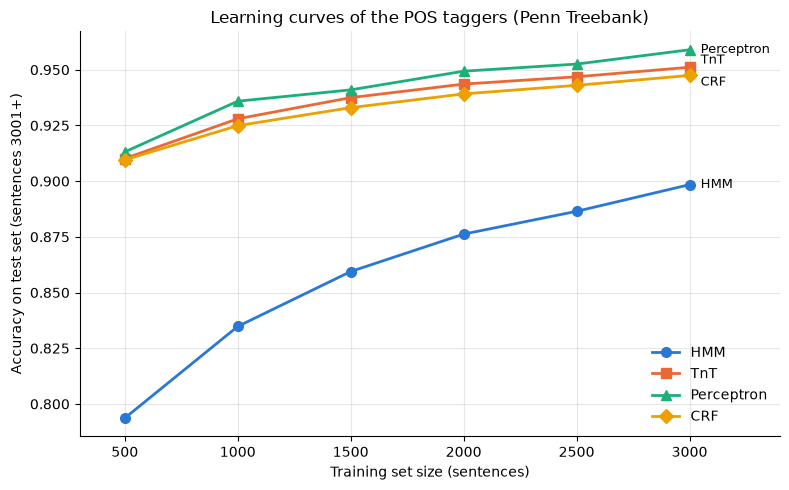

In [11]:
# Learning curves: one line per model type.
# Each model also has its own marker, so the lines can be told apart without colors.
colors = {"HMM": "#2a78d6", "TnT": "#eb6834", "Perceptron": "#1baf7a", "CRF": "#eda100"}
markers = {"HMM": "o", "TnT": "s", "Perceptron": "^", "CRF": "D"}
label_shift = {"TnT": 5, "CRF": -5}

fig, ax = plt.subplots(figsize=(8, 5))
for name in trainers:
    curve = accuracy_table[name]
    ax.plot(curve.index, curve.values, color=colors[name], marker=markers[name],
            linewidth=2, markersize=7, label=name)
    # Direct label at the end of each line (TnT and CRF are close, so shift them apart).
    ax.annotate(name, (curve.index[-1], curve.values[-1]), xytext=(8, label_shift.get(name, 0)),
                textcoords="offset points", va="center", fontsize=9)

ax.set_title("Learning curves of the POS taggers (Penn Treebank)")
ax.set_xlabel("Training set size (sentences)")
ax.set_ylabel("Accuracy on test set (sentences 3001+)")
ax.set_xticks(train_sizes)
ax.set_xlim(300, 3400)
ax.grid(alpha=0.3)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

In [12]:
# Accuracy on known and unknown words (words not seen in the 3000 training sentences).
train_words = {word for sent in sents[:3000] for word, tag in sent}
test_words = [[word for word, tag in sent] for sent in test]
gold_tags = [tag for sent in test for word, tag in sent]
is_unknown = [word not in train_words for sent in test for word, tag in sent]

print(f"Unknown words in the test set: {sum(is_unknown)} of {len(is_unknown)} ({sum(is_unknown) / len(is_unknown):.1%})\n")

for name, model in models.items():
    predicted = [tag for sent in model.tag_sents(test_words) for word, tag in sent]
    correct = [p == g for p, g in zip(predicted, gold_tags)]
    known_acc = sum(c for c, u in zip(correct, is_unknown) if not u) / is_unknown.count(False)
    unknown_acc = sum(c for c, u in zip(correct, is_unknown) if u) / is_unknown.count(True)
    print(f"{name:<10} known words: {known_acc:.4f}   unknown words: {unknown_acc:.4f}")

Unknown words in the test set: 2203 of 23165 (9.5%)

HMM        known words: 0.9552   unknown words: 0.3586
TnT        known words: 0.9688   unknown words: 0.7830
Perceptron known words: 0.9701   unknown words: 0.8534
CRF        known words: 0.9594   unknown words: 0.8343


## Question

### Which model would you select?

**The perceptron tagger.** The reasons are:

- **Highest accuracy at every training set size.** It goes from 0.9131 (500 sentences) to **0.9590** (3000 sentences), above TnT (0.9511), CRF (0.9475) and HMM (0.8984).
- **Best handling of unknown words.** 9.5% of the test words do not appear in the 3000 training sentences. On these words the perceptron reaches 0.8534, against 0.8343 (CRF), 0.7830 (TnT) and only 0.3586 (HMM). The perceptron and CRF use features of the word itself (such as suffixes and capitalization), so they can still guess the tag of a word they have never seen, while the HMM only relies on the emission probabilities learned from the training words.
- **It still improves with more data.** Its curve keeps rising until 3000 sentences (0.9526 → 0.9590 from 2500 to 3000), so more training data would probably still help.
- **Reasonable cost.** Training on 3000 sentences takes about 4 seconds and tagging the test set less than half a second. TnT is faster to train, and CRF is the slowest (about 10 seconds).

About the other models:

- **HMM** is clearly the worst at all sizes, mainly because of the unknown words. It is also the model that gains the most with more data (0.7937 → 0.8984), but it is still far below the others with 3000 sentences.
- **TnT** is a good alternative. It is very close to the perceptron (0.9511 vs 0.9590) and is the fastest model to train, so it could be preferred if training time was important.
- **CRF**, with the default features of NLTK's `CRFTagger`, is slightly below TnT and is the slowest to train, so it has no advantage here.

Note that the differences between the perceptron, TnT and CRF are small (less than 1.2 points with 3000 sentences) and come from a single train/test split, so the ranking between them is less reliable than the gap with the HMM.